# Portfolio Optimization Engine

This notebook builds an automated tool that finds the most efficient allocation of financial assets using **Modern Portfolio Theory (MPT)**.

### Workflow:
1. **Data Acquisition**: Fetch historical stock data using `yfinance`.
2. **Portfolio Mathematics**: Calculate expected returns, covariance matrix, and portfolio risk (volatility) using `numpy` and `pandas`.
3. **Monte Carlo Simulation**: Simulate thousands of random portfolio allocations to map out the **Efficient Frontier** and locate the optimal portfolio (maximum **Sharpe Ratio**).
4. **Visualization**: Plot the simulated portfolios, highlighting the optimal allocation.

In [8]:
# Install required library for fetching stock data
!pip install yfinance

In [9]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

# Set random seed for reproducibility
np.random.seed(42)

### 1. Download Historical Stock Data
We will define a set of diverse assets (e.g., Apple, Microsoft, Google, Amazon) and fetch daily adjusted closing prices for the past 5 years.

In [10]:
# Define assets and timeframe
tickers = ['AAPL', 'MSFT', 'GOOGL', 'AMZN']
start_date = '2019-01-01'
end_date = '2024-01-01'

# Download historical prices and explicitly extract Adjusted Close
df = yf.download(tickers, start=start_date, end=end_date)

# Handle yfinance multi-index column output safely
if 'Adj Close' in df.columns:
    data = df['Adj Close']
else:
    data = df['Close']

display(data.head())

/tmp/ipykernel_4504/2130390775.py:7: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(tickers, start=start_date, end=end_date)
[*********************100%***********************]  4 of 4 completed


Ticker,AAPL,AMZN,GOOGL,MSFT
Date,,,,
2019-01-02,37.436920,76.956497,52.236927,94.016167
2019-01-03,33.707924,75.014000,50.790192,90.557472
2019-01-04,35.146881,78.769501,53.395405,94.769272
2019-01-07,35.068665,81.475502,53.288921,94.890106
2019-01-08,35.737175,82.829002,53.756973,95.578110


### 2. Portfolio Mathematics
Calculate log returns, daily expected returns, annual expected returns, and the annual covariance matrix.

In [11]:
# Calculate daily log returns
log_returns = np.log(data / data.shift(1)).dropna()

# Calculate mean annual returns (assuming 252 trading days)
mean_returns = log_returns.mean() * 252

# Calculate annual covariance matrix
cov_matrix = log_returns.cov() * 252

print("Annualized Expected Returns:\n", mean_returns)
print("\nAnnualized Covariance Matrix:\n", cov_matrix)

Annualized Expected Returns:
 Ticker
AAPL     0.325871
AMZN     0.136374
GOOGL    0.195298
MSFT     0.273673
dtype: float64

Annualized Covariance Matrix:
 Ticker      AAPL      AMZN     GOOGL      MSFT
Ticker                                        
AAPL    0.104004  0.070512  0.069606  0.074851
AMZN    0.070512  0.124001  0.074245  0.073541
GOOGL   0.069606  0.074245  0.101372  0.073858
MSFT    0.074851  0.073541  0.073858  0.093052


### 3. Monte Carlo Simulation
We generate random weights, normalize them so they sum to 1, and compute the simulated portfolio returns, volatility, and Sharpe Ratio (assuming a risk-free rate of 0%).

In [12]:
num_portfolios = 10000
risk_free_rate = 0.0

# Initialize arrays to store results
all_weights = np.zeros((num_portfolios, len(tickers)))
ret_arr = np.zeros(num_portfolios)
vol_arr = np.zeros(num_portfolios)
sharpe_arr = np.zeros(num_portfolios)

for ind in range(num_portfolios):
    # Create random weights
    weights = np.array(np.random.random(len(tickers)))
    weights = weights / np.sum(weights)

    # Save weights
    all_weights[ind, :] = weights

    # Expected log return
    ret_arr[ind] = np.sum((mean_returns * weights))

    # Expected volatility
    vol_arr[ind] = np.sqrt(np.dot(weights.T, np.dot(cov_matrix, weights)))

    # Sharpe Ratio
    sharpe_arr[ind] = (ret_arr[ind] - risk_free_rate) / vol_arr[ind]

# Find the portfolio with the maximum Sharpe Ratio
max_sharpe_idx = sharpe_arr.argmax()
optimal_weights = all_weights[max_sharpe_idx]

print("Simulation completed.")
print(f"Max Sharpe Ratio achieved: {sharpe_arr[max_sharpe_idx]:.2f}")
for t, w in zip(tickers, optimal_weights):
    print(f"Allocation for {t}: {w:.2%}")

Simulation completed.
Max Sharpe Ratio achieved: 1.03
Allocation for AAPL: 64.29%
Allocation for MSFT: 0.75%
Allocation for GOOGL: 0.39%
Allocation for AMZN: 34.57%


### 4. Efficient Frontier Visualization
Let's plot all simulated portfolios, highlighting the portfolio with the optimal allocation.

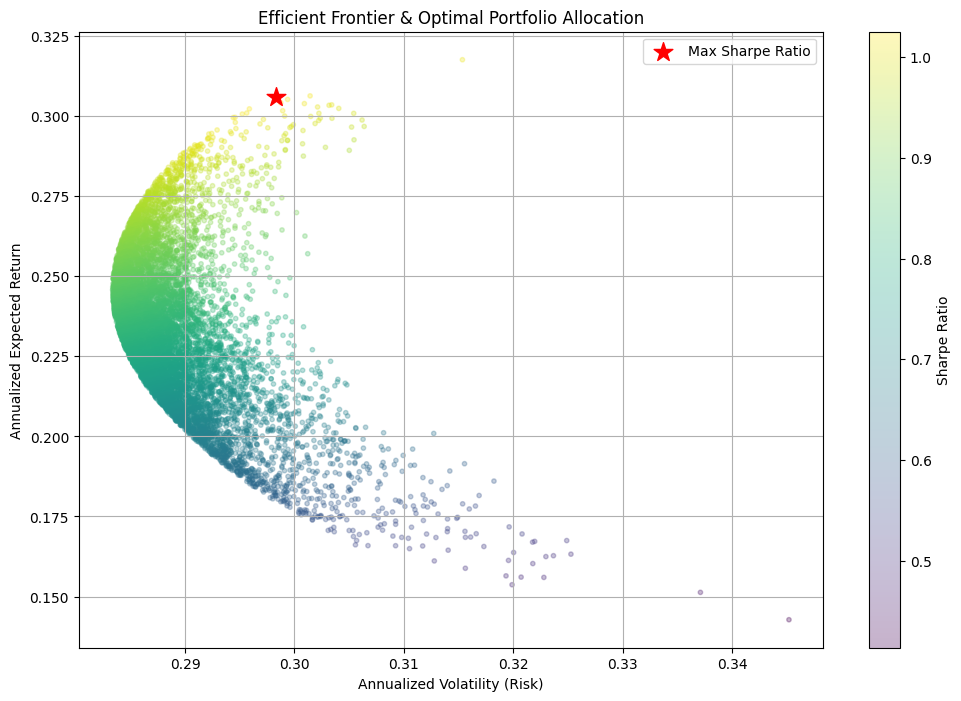

In [13]:
plt.figure(figsize=(12, 8))
plt.scatter(vol_arr, ret_arr, c=sharpe_arr, cmap='viridis', marker='o', s=10, alpha=0.3)
plt.colorbar(label='Sharpe Ratio')

# Highlight the optimal portfolio
plt.scatter(vol_arr[max_sharpe_idx], ret_arr[max_sharpe_idx], c='red', marker='*', s=200, label='Max Sharpe Ratio')

plt.title('Efficient Frontier & Optimal Portfolio Allocation')
plt.xlabel('Annualized Volatility (Risk)')
plt.ylabel('Annualized Expected Return')
plt.legend(labelspacing=0.8)
plt.grid(True)
plt.show()